In [1]:
from pathlib import Path
import torch

from configs.swin3d_small import TRAIN_CONFIG
from datasets.belize_laz_dataset import create_dataloaders
from models.swin3d_model import Model

from visualization.vis import (
    visualize_tile,
    visualize_prediction_errors,
    find_archaeological_tiles,
    print_archaeological_tiles,

    evaluate_test_tiles,
    find_extreme_test_tiles,
    print_extreme_test_tiles,
)

/work/archcomplab/ssaraf/envs/maya_env/lib/python3.10/site-packages/MinkowskiEngine/__init__.py:36: UserWarning: The environment variable `OMP_NUM_THREADS` not set. MinkowskiEngine will automatically set `OMP_NUM_THREADS=16`. If you want to set `OMP_NUM_THREADS` manually, please export it on the command line before running a python script. e.g. `export OMP_NUM_THREADS=12; python your_program.py`. It is recommended to set it below 24.
  warnings.warn(


In [2]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla V100-PCIE-32GB


In [3]:
train_loader, validation_loader, test_loader = create_dataloaders(
    split_dir="dataset_splits",
    batch_size=TRAIN_CONFIG["batch_size"],
    voxel_max=TRAIN_CONFIG["voxel_max"],
    num_workers=4,
    augmentation_ratio=TRAIN_CONFIG["augmentation_ratio"],
)

print("Test tiles:", len(test_loader.dataset))
print("Test batches:", len(test_loader))

Test tiles: 80
Test batches: 5


In [4]:
model = Model(
    num_classes=TRAIN_CONFIG["num_classes"],
    in_channels=4,
).to(device)

print("Model created.")

Model created.


In [5]:
BEST_CHECKPOINT = Path(
    "/mnt/nrdstor/archcomplab/ssaraf/"
    "swin3d_checkpoints/"
    "dice_vicinity/"
    "swin3d_dice_vicinity_best_02.pth"
)

print("Checkpoint exists:", BEST_CHECKPOINT.exists())
print("Checkpoint:", BEST_CHECKPOINT)

Checkpoint exists: True
Checkpoint: /mnt/nrdstor/archcomplab/ssaraf/swin3d_checkpoints/dice_vicinity/swin3d_dice_vicinity_best_02.pth


In [6]:
checkpoint = torch.load(
    BEST_CHECKPOINT,
    map_location=device,
)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Checkpoint epoch:", checkpoint.get("epoch", "unknown"))

/tmp/ipykernel_68070/2326245694.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(


Checkpoint epoch: 55


In [7]:
archaeological_tiles = find_archaeological_tiles(
    dataset=test_loader.dataset,
    minimum_archaeology_points=100,
    sort_by="archaeology",
)

print_archaeological_tiles(
    archaeological_tiles,
    limit=20,
)

Archaeological tiles found: 76

 Index   Structure    Plazuela  Total Arch  File
------------------------------------------------------------------------------------------
    71           0      19,475      19,475  100m_272400_1800600_remesh_grid_slope.laz
    61      14,569         133      14,702  100m_278700_1796700_remesh_grid_slope.laz
     9           0      14,655      14,655  100m_272000_1799500_remesh_grid_slope.laz
    28           0      11,965      11,965  100m_272300_1800700_remesh_grid_slope.laz
    49       2,042       9,364      11,406  100m_277400_1795300_remesh_grid_slope.laz
    27       3,441       7,952      11,393  100m_277500_1797700_remesh_grid_slope.laz
     3           0       9,425       9,425  100m_275000_1800600_remesh_grid_slope.laz
     0         972       7,653       8,625  100m_278500_1799200_remesh_grid_slope.laz
    53         526       7,744       8,270  100m_276800_1796800_remesh_grid_slope.laz
    14         806       7,255       8,061  100m_27610

In [8]:
tile_index = archaeological_tiles[0]["index"] if archaeological_tiles else 0
print("Selected tile:", tile_index)

Selected tile: 71


In [9]:
tile_index = 9

/work/archcomplab/ssaraf/envs/maya_env/lib/python3.10/site-packages/torch/functional.py:534: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at ../aten/src/ATen/native/TensorShape.cpp:3595.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/work/archcomplab/ssaraf/software/Swin3D/Swin3D/modules/swin3d_layers.py:239: UserWarning: The torch.cuda.*DtypeTensor constructors are no longer recommended. It's best to use methods such as torch.tensor(data, dtype=*, device='cuda') to create tensors. (Triggered internally at ../torch/csrc/tensor/python_tensor.cpp:78.)
  offset = torch.cuda.IntTensor(offset)


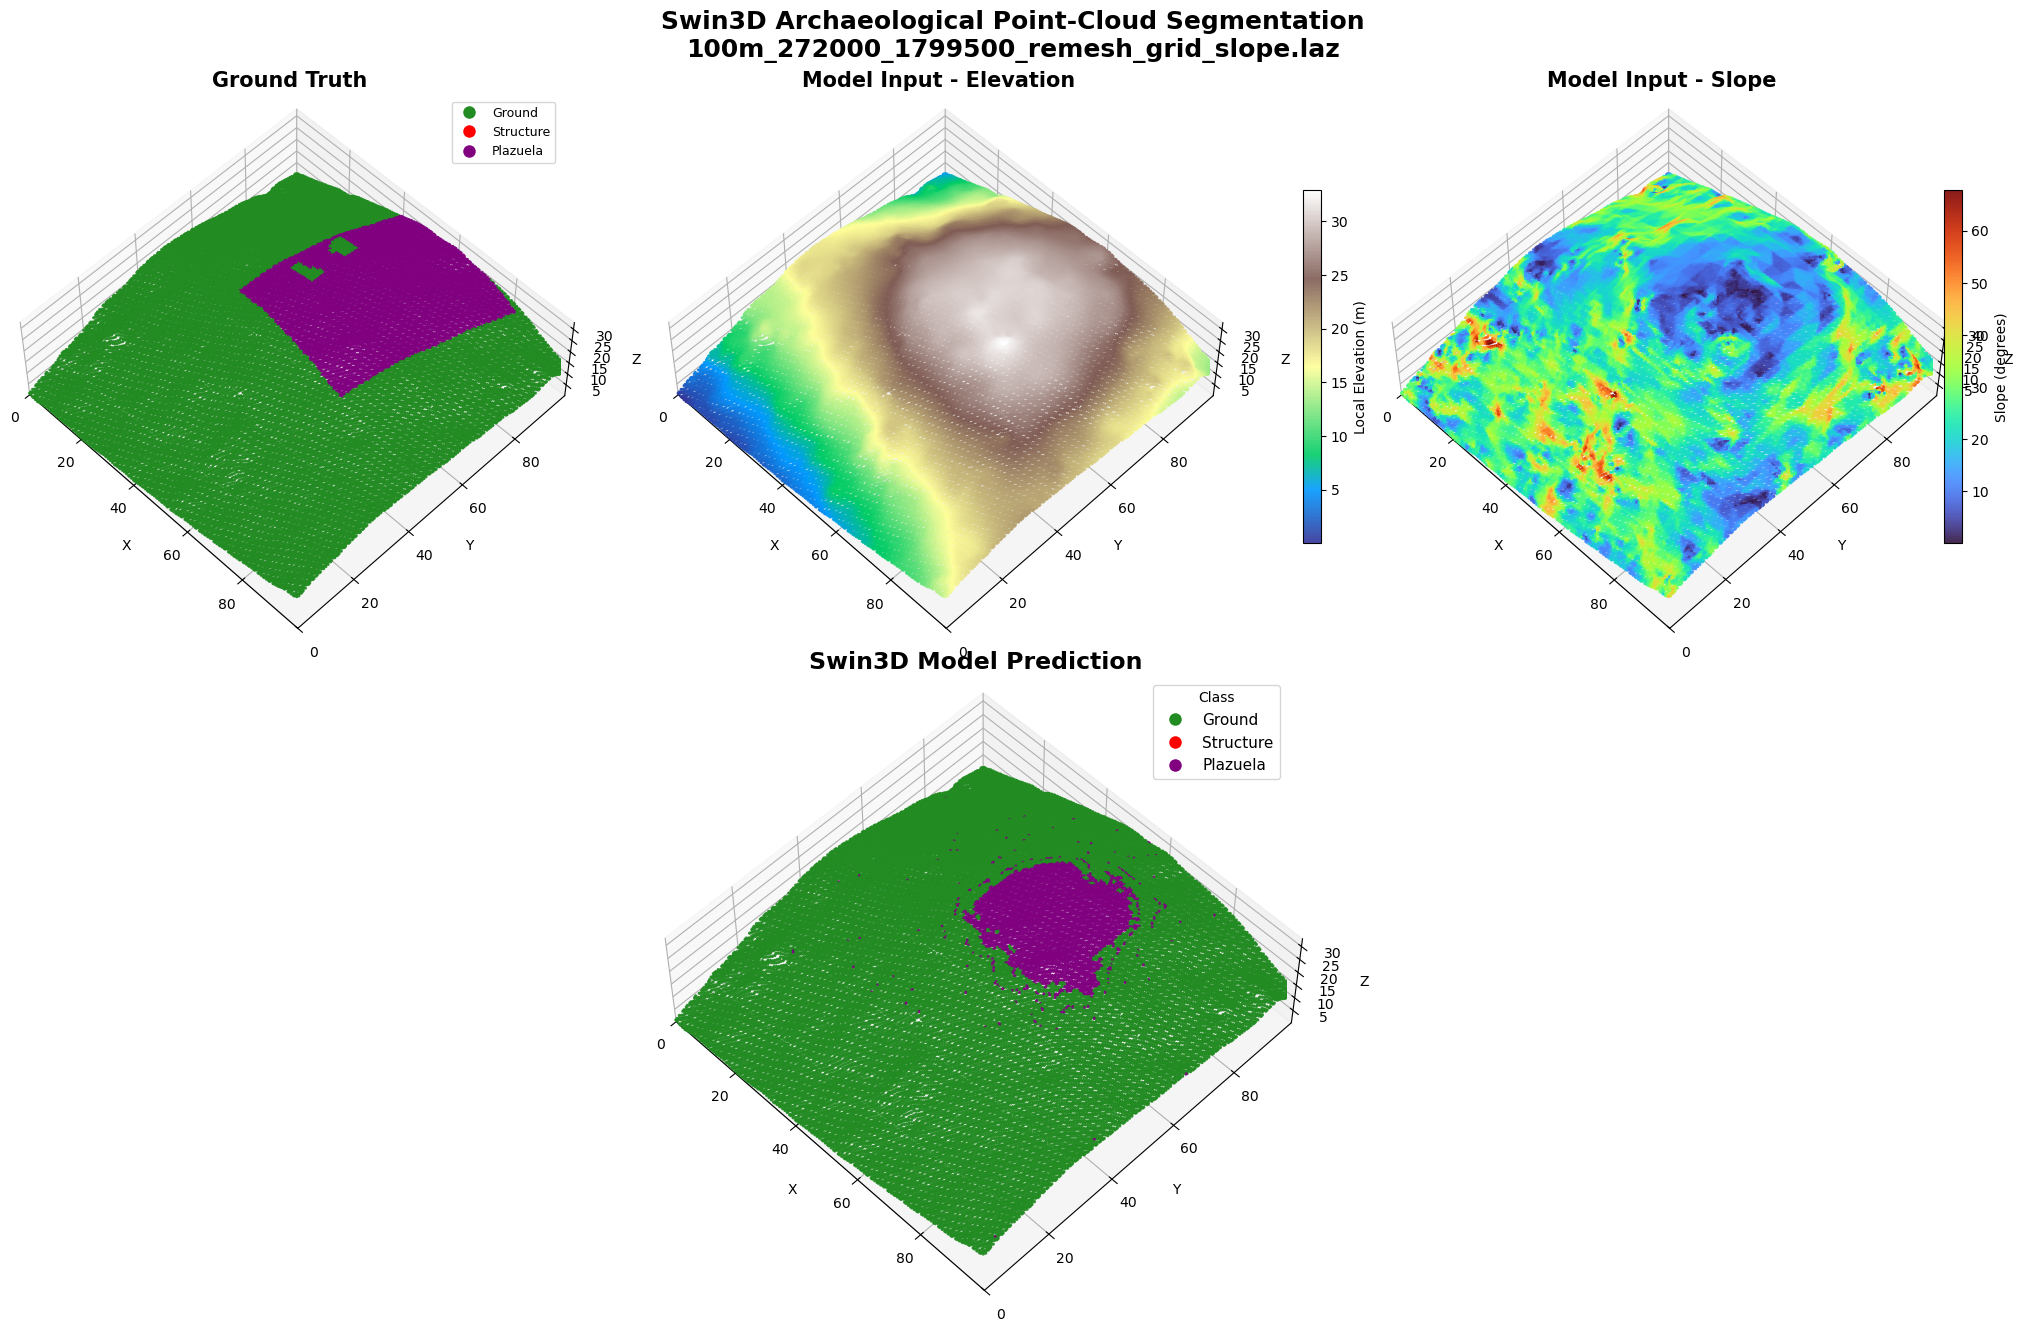


Tile: 100m_272000_1799500_remesh_grid_slope.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     50,345
  Structure :          0
  Plazuela  :     14,655

Prediction counts:
  Ground    :     58,902
  Structure :          0
  Plazuela  :      6,098

Point accuracy: 0.8623


In [10]:
visualization_output = visualize_tile(
    model=model,
    dataset=test_loader.dataset,
    tile_index=tile_index,
    device=device,
    max_plot_points=40000,
    point_size=1.5,
    elevation_angle=55,
    azimuth_angle=-45,
)

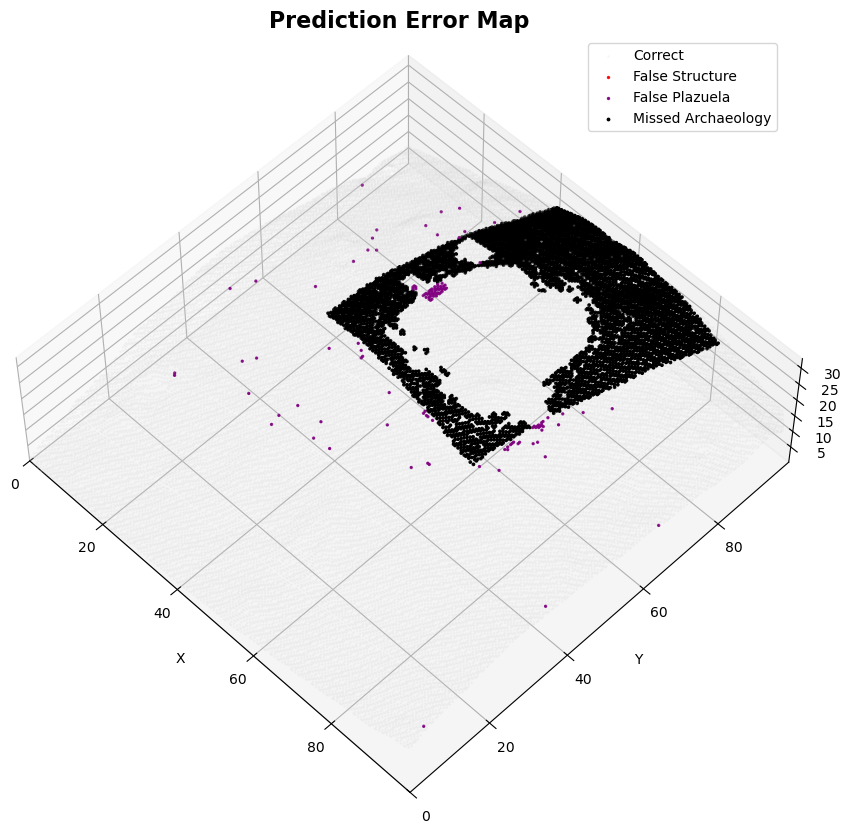

{'correct': 34496, 'false_structure': 0, 'false_plazuela': 125, 'missed_archaeology': 5379}


In [11]:
error_counts = visualize_prediction_errors(
    visualization_output,
    max_plot_points=40000,
    point_size=2.0,
    elevation_angle=55,
    azimuth_angle=-45,
)

print(error_counts)

In [12]:
tile_results = evaluate_test_tiles(
    model=model,
    dataset=test_loader.dataset,
    device=device,
    print_progress=True,
)

Evaluated tile 001/080
Evaluated tile 010/080
Evaluated tile 020/080
Evaluated tile 030/080
Evaluated tile 040/080
Evaluated tile 050/080
Evaluated tile 060/080
Evaluated tile 070/080
Evaluated tile 080/080


In [13]:
extreme_tiles = find_extreme_test_tiles(
    tile_results
)

print_extreme_test_tiles(
    extreme_tiles
)


highest_accuracy
Tile index: 75
Accuracy: 0.9916
False-positive count: 548
False-positive rate: 0.0086
Structure false positives: 0
Plazuela false positives: 548
GT Structure: 0
GT Plazuela: 1,283
File: 100m_273800_1796700_remesh_grid_slope.laz

highest_false_positive_count
Tile index: 42
Accuracy: 0.7161
False-positive count: 17,452
False-positive rate: 0.2822
Structure false positives: 398
Plazuela false positives: 17,054
GT Structure: 0
GT Plazuela: 3,165
File: 100m_272900_1796600_remesh_grid_slope.laz

highest_false_positive_rate
Tile index: 42
Accuracy: 0.7161
False-positive count: 17,452
False-positive rate: 0.2822
Structure false positives: 398
Plazuela false positives: 17,054
GT Structure: 0
GT Plazuela: 3,165
File: 100m_272900_1796600_remesh_grid_slope.laz


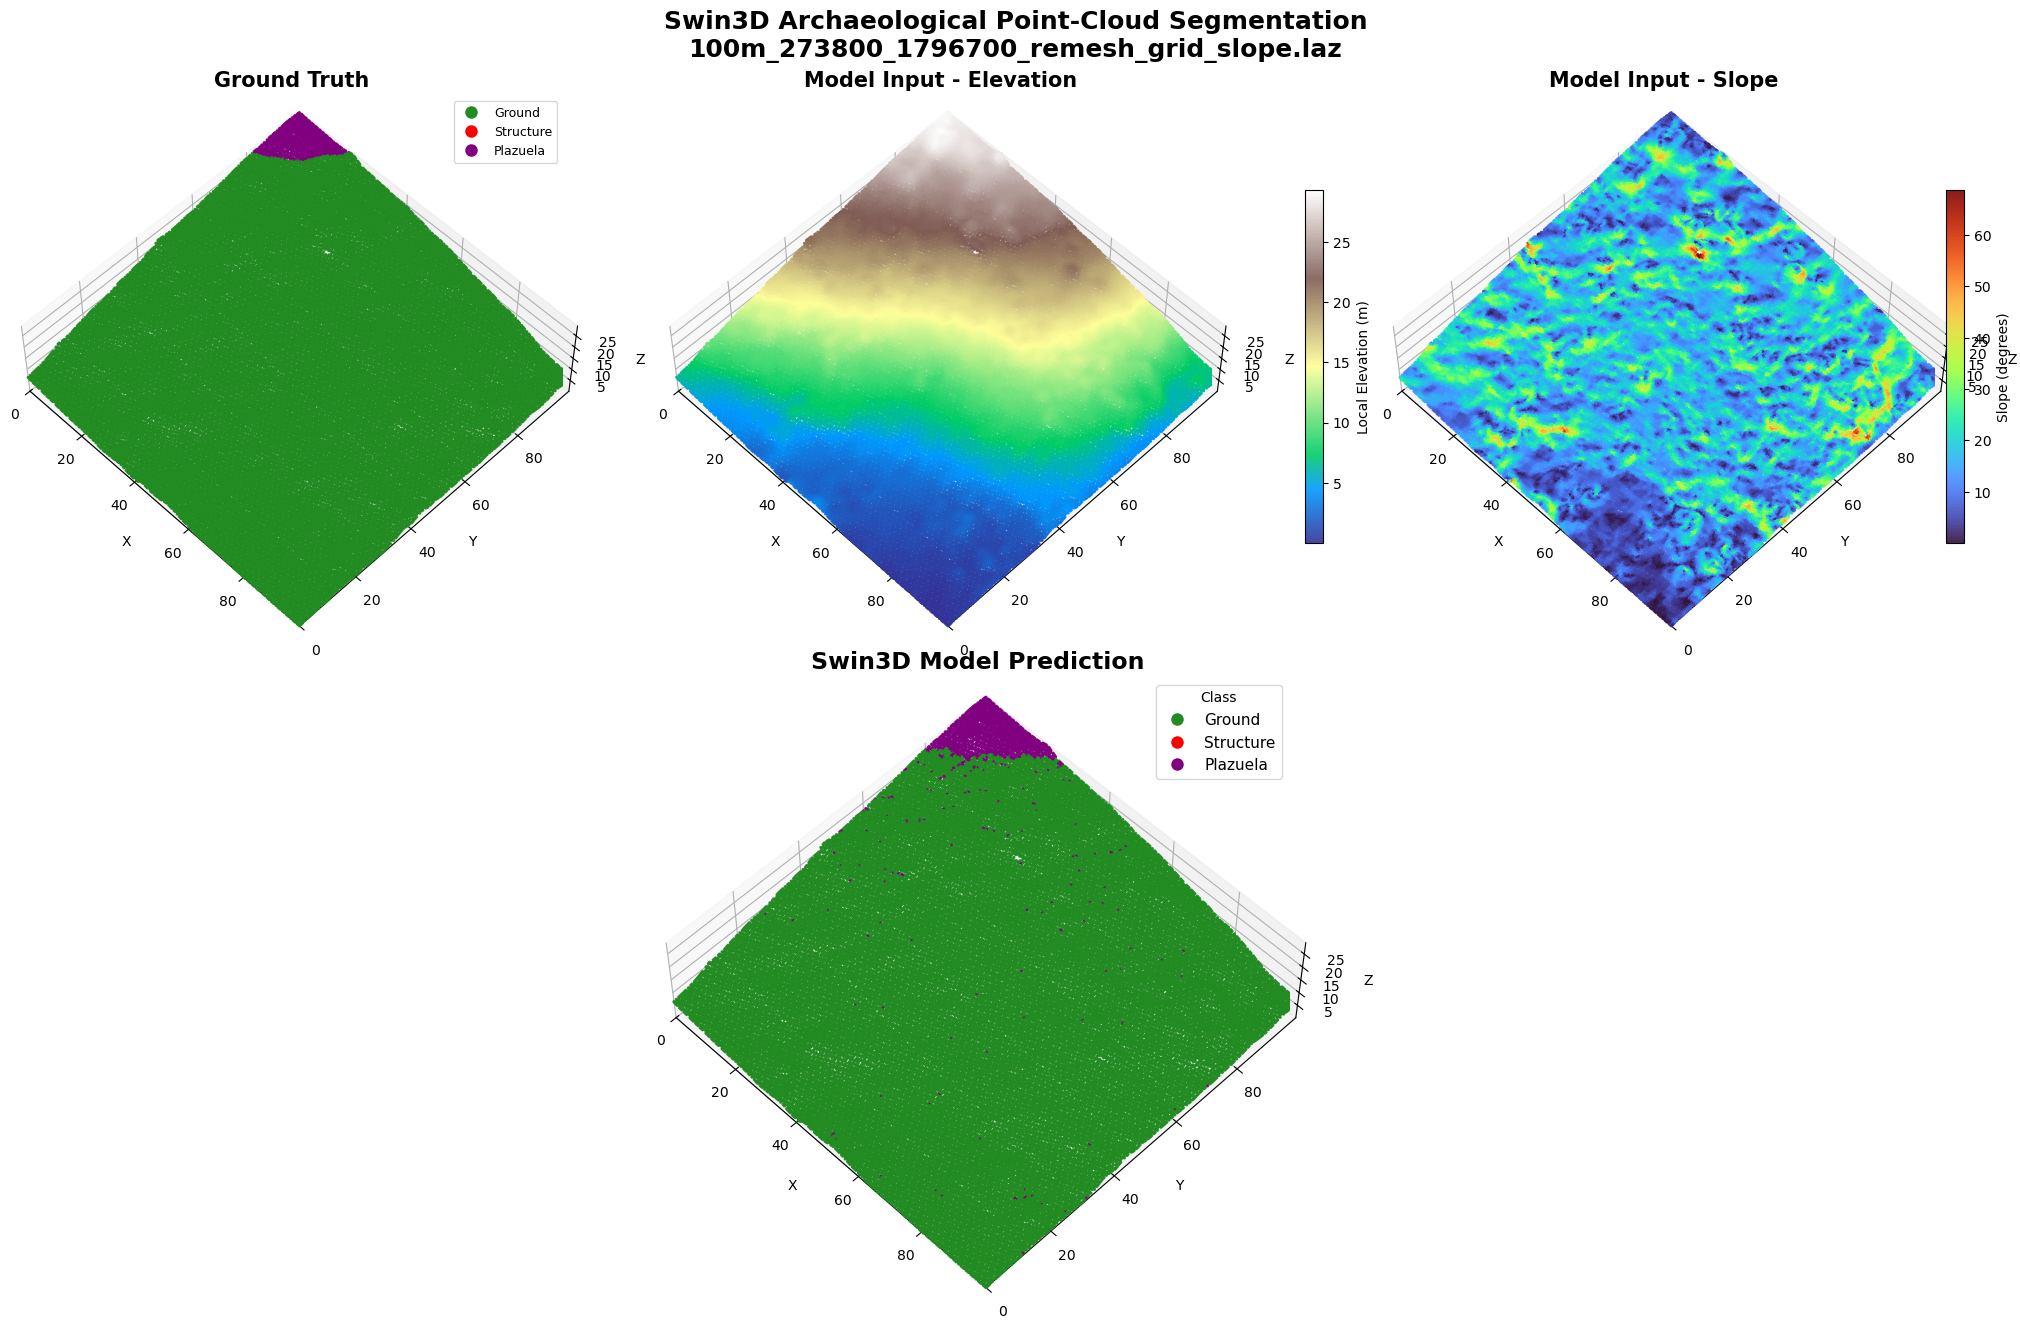


Tile: 100m_273800_1796700_remesh_grid_slope.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     63,717
  Structure :          0
  Plazuela  :      1,283

Prediction counts:
  Ground    :     63,174
  Structure :          0
  Plazuela  :      1,826

Point accuracy: 0.9916


In [14]:
best_accuracy_index = (
    extreme_tiles[
        "highest_accuracy"
    ]["index"]
)

best_accuracy_output = visualize_tile(
    model=model,
    dataset=test_loader.dataset,
    tile_index=best_accuracy_index,
    device=device,

    max_plot_points=50_000,
    point_size=1.5,

    elevation_angle=55,
    azimuth_angle=-45,
)

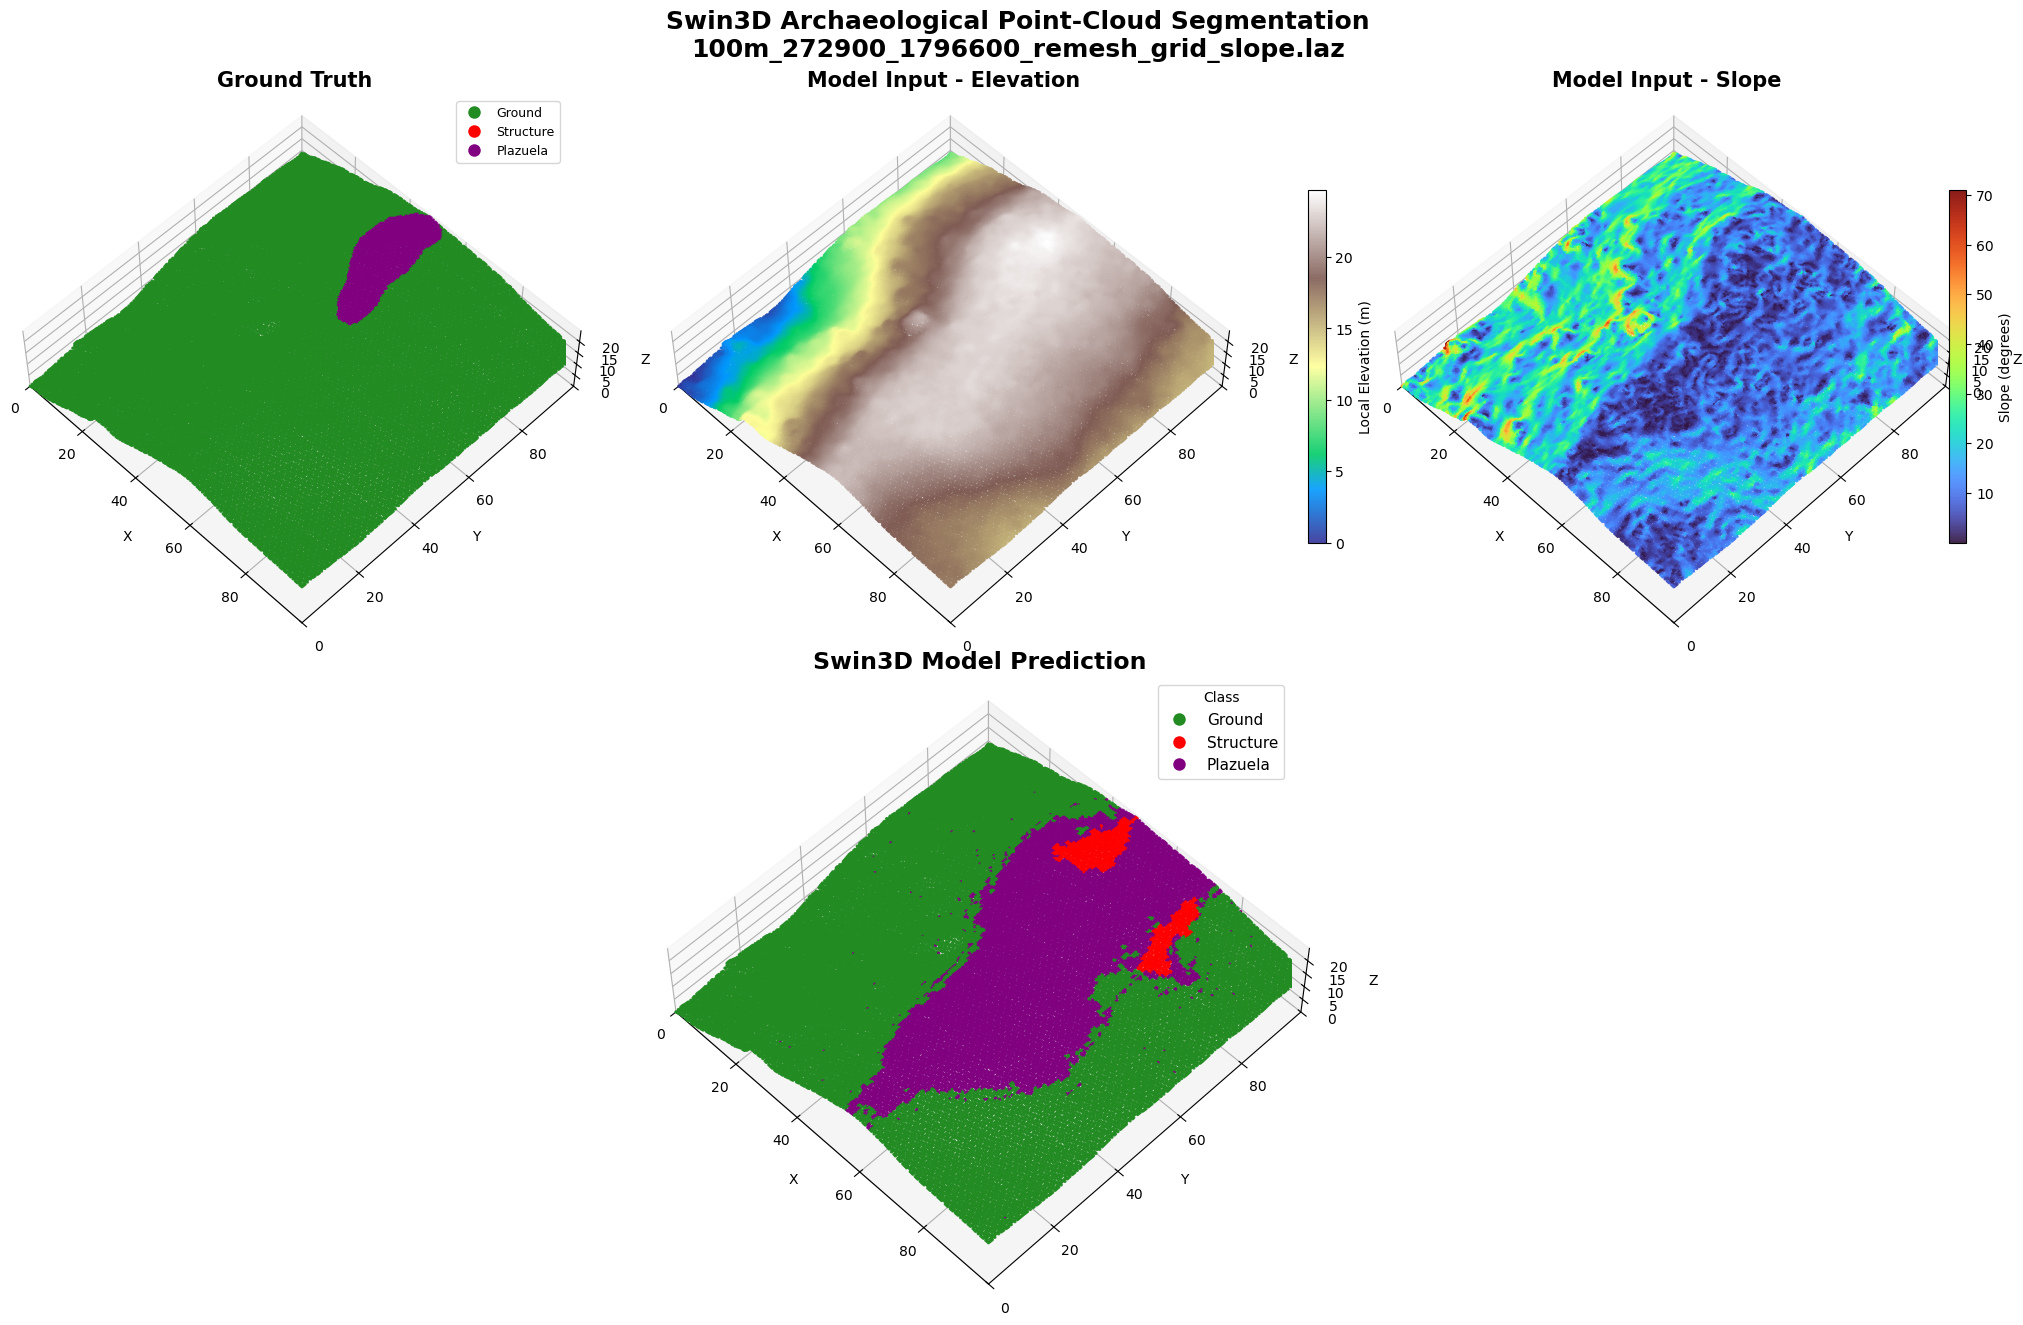


Tile: 100m_272900_1796600_remesh_grid_slope.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     61,835
  Structure :          0
  Plazuela  :      3,165

Prediction counts:
  Ground    :     44,632
  Structure :      1,613
  Plazuela  :     18,755

Point accuracy: 0.7195


In [15]:
highest_fp_index = (
    extreme_tiles[
        "highest_false_positive_count"
    ]["index"]
)

highest_fp_output = visualize_tile(
    model=model,
    dataset=test_loader.dataset,
    tile_index=highest_fp_index,
    device=device,

    max_plot_points=50_000,
    point_size=1.5,

    elevation_angle=55,
    azimuth_angle=-45,
)

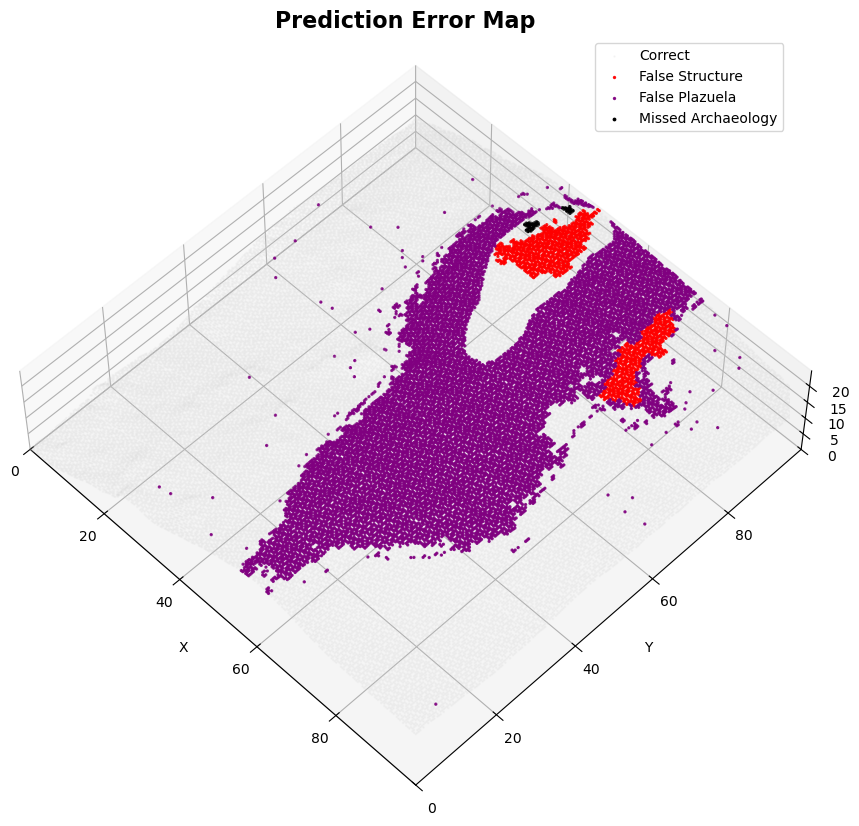

{'correct': 35975,
 'false_structure': 1242,
 'false_plazuela': 12746,
 'missed_archaeology': 37}

In [16]:
visualize_prediction_errors(
    highest_fp_output,

    max_plot_points=50_000,
    point_size=2.0,

    elevation_angle=55,
    azimuth_angle=-45,
)

In [17]:
from visualization.vis import (
    spatial_filter_predictions,
    compare_before_after_filter,
    visualize_filtered_prediction
)

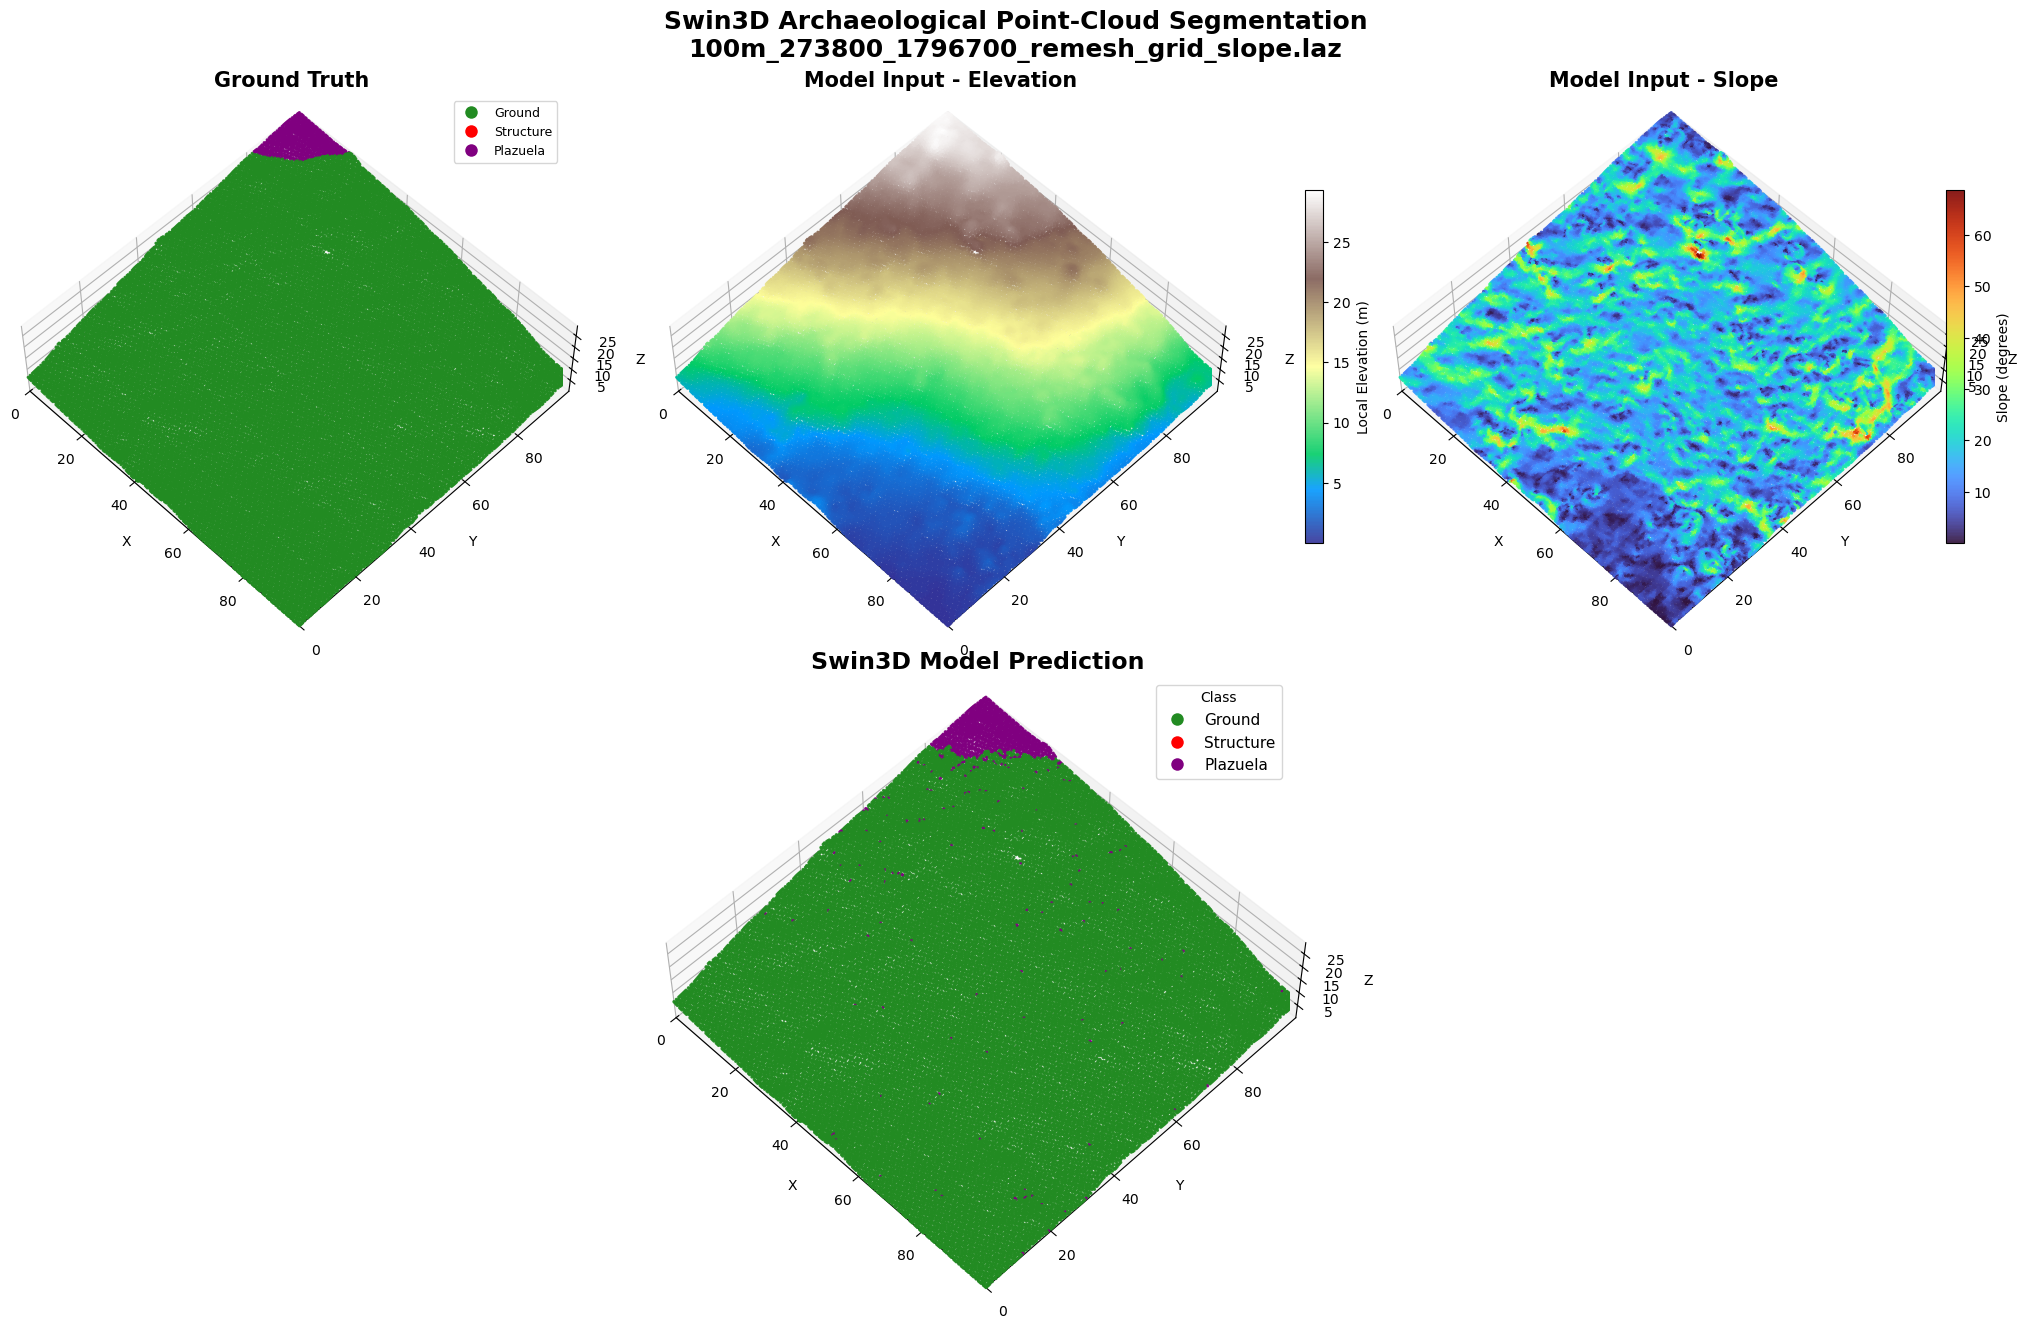


Tile: 100m_273800_1796700_remesh_grid_slope.laz
Number of points: 65,000

Ground truth counts:
  Ground    :     63,717
  Structure :          0
  Plazuela  :      1,283

Prediction counts:
  Ground    :     63,273
  Structure :          0
  Plazuela  :      1,727

Point accuracy: 0.9928


In [18]:
visualization_output = visualize_tile(
    model=model,
    dataset=test_loader.dataset,
    tile_index=best_accuracy_index,
    device=device,

    max_plot_points=50_000,
    point_size=1.5,

    elevation_angle=55,
    azimuth_angle=-45,
)

In [19]:
filtered_predictions, filter_info = (
    spatial_filter_predictions(
        coords=visualization_output[
            "coords_np"
        ],

        predictions=visualization_output[
            "predictions_np"
        ],

        cell_size=1.0,

        structure_min_cells=8,
        plazuela_min_cells=15,

        opening_iterations=1,
        closing_iterations=0,

        verbose=True,
    )
)


Spatial filtering
-----------------

Structure
  Points before: 0
  Points after: 0
  Points removed: 0
  Components before: 0
  Components after: 0

Plazuela
  Points before: 1,727
  Points after: 1,498
  Points removed: 229
  Components before: 118
  Components after: 1


In [20]:
comparison = compare_before_after_filter(
    labels=visualization_output[
        "labels_np"
    ],

    original_predictions=(
        visualization_output[
            "predictions_np"
        ]
    ),

    filtered_predictions=(
        filtered_predictions
    ),
)


FILTER PERFORMANCE
Accuracy before: 0.9928
Accuracy after:  0.9962
Difference:      +0.0034

Ground
  Precision: 0.9998 -> 0.9997
  Recall:    0.9929 -> 0.9964
  FP:        11 -> 16

Structure
  Precision: 0.0000 -> 0.0000
  Recall:    0.0000 -> 0.0000
  FP:        0 -> 0

Plazuela
  Precision: 0.7365 -> 0.8458
  Recall:    0.9914 -> 0.9875
  FP:        455 -> 231



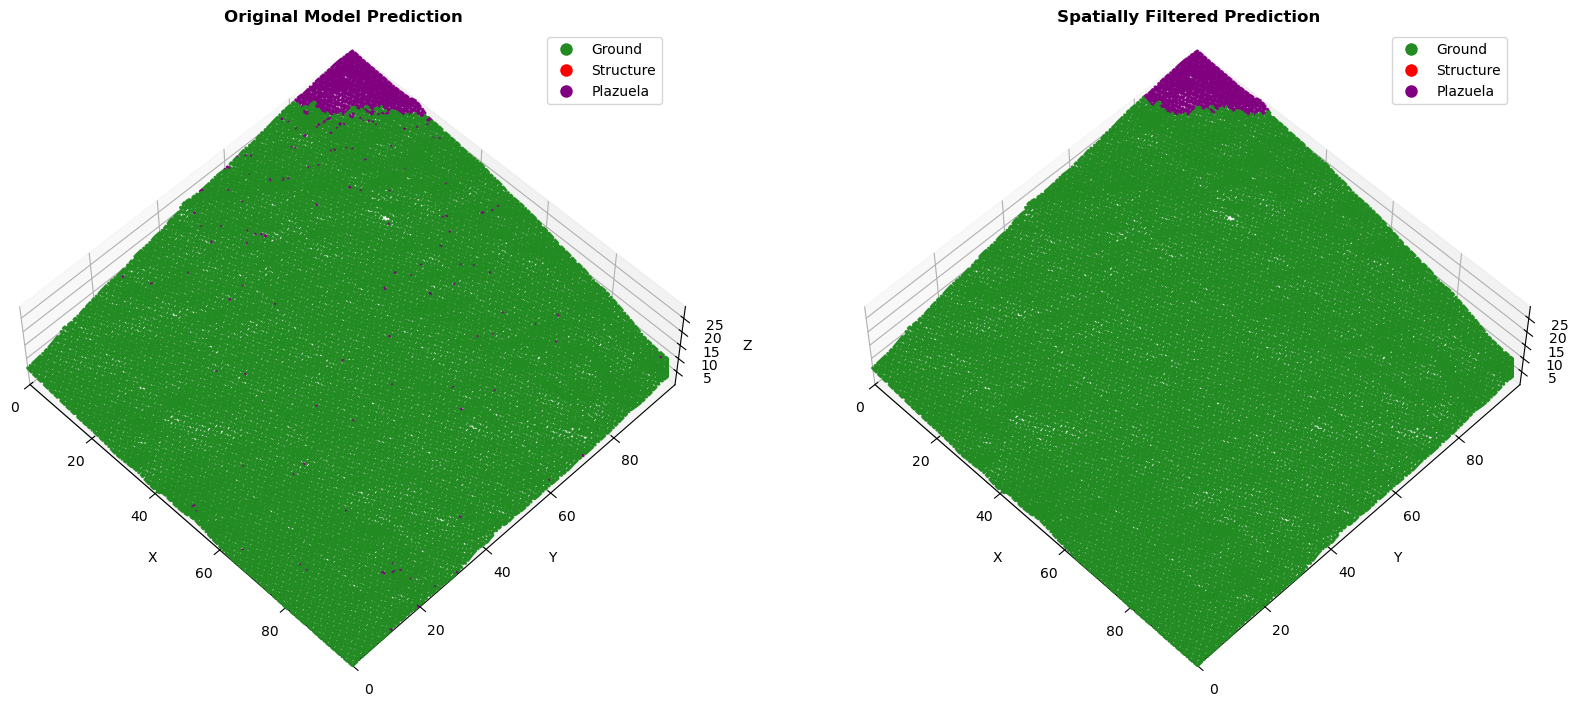


FILTER PERFORMANCE
Accuracy before: 0.9928
Accuracy after:  0.9962
Difference:      +0.0034

Ground
  Precision: 0.9998 -> 0.9997
  Recall:    0.9929 -> 0.9964
  FP:        11 -> 16

Structure
  Precision: 0.0000 -> 0.0000
  Recall:    0.0000 -> 0.0000
  FP:        0 -> 0

Plazuela
  Precision: 0.7365 -> 0.8458
  Recall:    0.9914 -> 0.9875
  FP:        455 -> 231



In [21]:
visualize_filtered_prediction(
    visualization_output=(
        visualization_output
    ),

    filtered_predictions=(
        filtered_predictions
    ),

    max_plot_points=50_000,
)